# Soil Structural Data Comparison

This notebook simply compares several different sets of soil structural data, clarifying how they can be used and noting their imperfections.

To run an integrated hydrology simulation, we need at least:

* porosity [-]
* permeability [m^2]
* van Genuchten properties (n [-], alpha [Pa^-1], and residual saturation [-])

across the entire domain.  These vary both spatially and with depth.

There are two ways to specify this data:

1. as a raster, with every cell having its own value
2. as an indexed field, which combines a "structural model" that identifies which media each cell is in, plus a lookup table mapping media to properties.

For a structural model, we typically define two or three layers:  bedrock, a geologic layer, and a soil layer.  For the horizontal component, it is most convenient to work with formations -- horizontal shapes whose bodies are assumed to be homogeneous within the shape and layer.  

We can work with fields of porosity and permeability.  Currently ATS does not support fields of van Genuchten parameters, but this could be changed relatively simply.

**There is no one right or best model!**  This notebook exists to let the user set their domain and then explore the various datasets to see which look the best on their domain.

In [1]:
# these can be turned on for development work
%load_ext autoreload
%autoreload 2

In [2]:
import watershed_workflow.io
watershed_workflow.io.setupLogging(1)

In [3]:
import numpy as np
import xarray as xr
import matplotlib.colors as mcolors
import matplotlib.cm as mcm
from matplotlib import pyplot as plt

import watershed_workflow
import watershed_workflow.plot
import watershed_workflow.crs
import watershed_workflow.io
import watershed_workflow.utils
import watershed_workflow.properties
import watershed_workflow.sources


In [4]:
# user input -- choose the HUC to work on
huc = '140200010204'
crs = watershed_workflow.crs.default_crs

2026-07-24 21:32:38,349 - root - INFO: fixing column: geometry


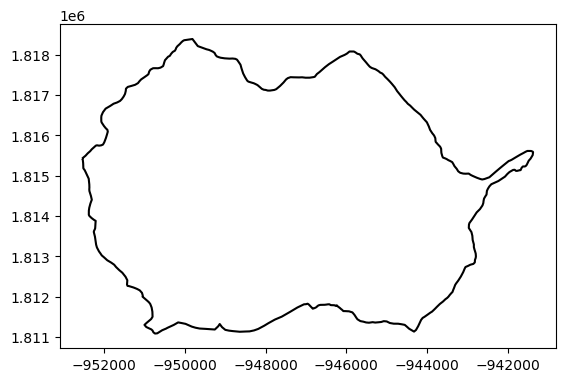

In [5]:
# collect the HUCs from WBD
watershed = watershed_workflow.sources.ManagerWBD().getShapesByID([huc,], out_crs=crs)

# plot what we have so far -- an image of the HUC
watershed.exterior.plot(color='k')

# domain bounds used to set xlim/ylim on all plots
xmin, ymin, xmax, ymax = watershed.geometry.total_bounds
_pad = (xmax - xmin) * 0.02
domain_xlim = (xmin - _pad, xmax + _pad)
domain_ylim = (ymin - _pad, ymax + _pad)

## Available Products

The following products are routinely available across the US (or globally).

### GLHYMPS

The Global Hydrogeology Maps product provides data by shapefile/formation, and provides:

* porosity
* permeability
* depth-to-bedrock

This dataset is fairly complete, but there are some oddities -- most notably much of the DTB field seems to be 0, and a significant subset of the porosity are 0 (mostly alluvial sediments, WW corrects this).  But the data is pretty good and complete.  However, it is missing WRM parameters (or equivalently, texture information).

Gleeson, T., Moosdorf, N., Hartmann, J., & van Beek, L. P. H. (2014). A glimpse beneath earth's surface: GLobal HYdrogeology MaPS (GLHYMPS) of permeability and porosity. *Geophysical Research Letters*, 41(11), 3891–3898. https://doi.org/10.1029/2014GL059856

Huscroft, J., Gleeson, T., Hartmann, J., & Börker, J. (2018). Compiling and mapping global permeability of the unconsolidated and consolidated Earth: GLobal HYdrogeology MaPS 2.0 (GLHYMPS 2.0). *Geophysical Research Letters*, 45(4), 1897–1904. https://doi.org/10.1002/2017GL075860

In [6]:
# first let's look at GLYHMPS
# -- get the data
glhymps_mgr = watershed_workflow.sources.ManagerGLHYMPS()
gl_gdf = glhymps_mgr.getShapesByGeometry(watershed, out_crs=crs)


2026-07-24 21:32:38,583 - root - INFO:   Shapes manager: buffered+snapped query box = (-11965520.459519299, 3933522.1022809995, -11864010.211718498, 4035032.3500817996)
2026-07-24 21:32:38,584 - root - INFO:   from file: /Users/uec/code/watershed_workflow/data/soil_structure/GLHYMPS/dataverse_https/GLHYMPS.shp
2026-07-24 21:32:46,443 - root - INFO: fixing column: geometry


In [7]:
# convert it to standard ATS datasets
gl_gdf = watershed_workflow.properties.soil.mangleGLHYMPSProperties(gl_gdf)
gl_gdf

,ID,name,source,permeability [m^2],logk_stdev [-],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],geometry
259,715639,GLHYMPS-715639,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,"MULTIPOLYGON (((-941668.093 1811291.15, -94199..."
278,715707,GLHYMPS-715707,GLHYMPS,1.000000e-13,2.00,0.22,0.000294,1.5,0.01,"MULTIPOLYGON (((-942876.044 1814661.916, -9427..."
287,715766,GLHYMPS-715766,GLHYMPS,3.162278e-13,1.80,0.09,0.000817,1.5,0.01,"POLYGON ((-947358.28 1813697.646, -948118.709 ..."
289,715779,GLHYMPS-715779,GLHYMPS,1.000000e-13,2.00,0.22,0.000294,1.5,0.01,"POLYGON ((-944025.909 1813309.319, -944527.763..."
291,715796,GLHYMPS-715796,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,"MULTIPOLYGON (((-933660.561 1797293.054, -9335..."
894,726604,GLHYMPS-726604,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,"MULTIPOLYGON (((-941747.425 1812754.646, -9418..."
897,726608,GLHYMPS-726608,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,"MULTIPOLYGON (((-953864.501 1813999.086, -9542..."
917,726639,GLHYMPS-726639,GLHYMPS,3.162278e-13,1.80,0.09,0.000817,1.5,0.01,"POLYGON ((-948778.786 1815596.525, -948024.977..."
918,726642,GLHYMPS-726642,GLHYMPS,1.000000e-13,2.00,0.22,0.000294,1.5,0.01,"MULTIPOLYGON (((-944367.697 1813260.891, -9445..."
935,726664,GLHYMPS-726664,GLHYMPS,1.000000e-13,2.00,0.22,0.000294,1.5,0.01,"POLYGON ((-952109.643 1813503.499, -951346.338..."


In [8]:
# -- print extent of properties
gl_logK = np.log10(gl_gdf['permeability [m^2]'][:])
print('logK', gl_logK.min(), gl_logK.max())

poro = gl_gdf['porosity [-]']
print('poro', poro.min(), poro.max())

logK -15.2 -10.52
poro 0.09 0.22


In [9]:
gl_gdf.crs

<Projected CRS: EPSG:5070>
Name: NAD83 / Conus Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - CONUS onshore - Alabama; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming.
- bounds: (-124.79, 24.41, -66.91, 49.38)
Coordinate Operation:
- name: Conus Albers
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [10]:
# -- color a raster by the polygons to see the structure
gl_color = watershed_workflow.utils.rasterizeGeoDataFrame(gl_gdf, 'ID', 10)                                                        
gl_color = gl_color.rio.clip(watershed.geometry, watershed.crs)


Text(0.5, 1.0, 'GLHYMPS')

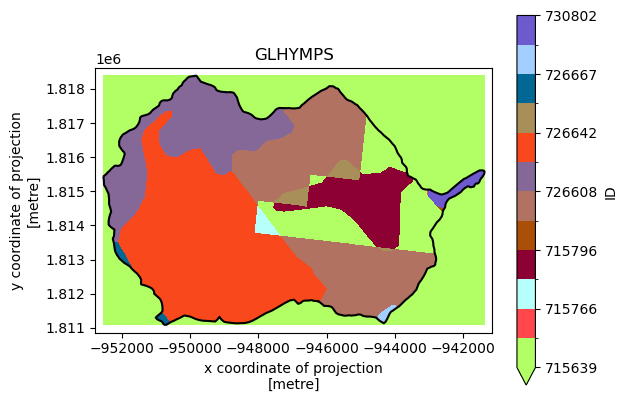

In [11]:
# plot the formations
fig, ax = plt.subplots()
unique_inds, gl_cmap, gl_norm, gl_ticks, gl_labels = \
       watershed_workflow.plot.createIndexedColormap(gl_gdf['ID'])

gl_color.plot.imshow(ax=ax, cmap=gl_cmap, norm=gl_norm)
watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
ax.set_xlim(domain_xlim)
ax.set_ylim(domain_ylim)
ax.set_title('GLHYMPS')

In [12]:
# generate glhymps porosity, permeability fields
# -- porosity
gl_poro = watershed_workflow.utils.rasterizeGeoDataFrame(gl_gdf, 'porosity [-]', 10, nodata=np.nan)
gl_poro = gl_poro.rio.clip(watershed.geometry, watershed.crs)

# -- permeability
gl_perm = watershed_workflow.utils.rasterizeGeoDataFrame(gl_gdf, 'permeability [m^2]', 10, nodata=np.nan)
gl_perm = gl_perm.rio.clip(watershed.geometry, watershed.crs)



Text(0.5, 1.0, 'log permeability [m^2]')

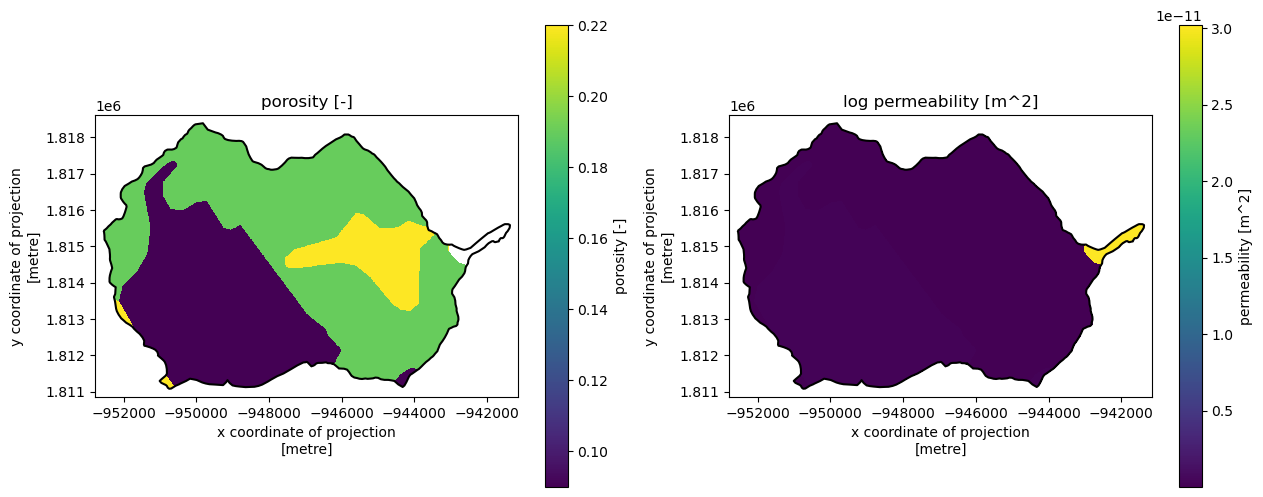

In [13]:
# plot porosity and perm for glhymps
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
gl_poro.plot.imshow(ax=axs[0])
gl_perm.plot.imshow(ax=axs[1])
for ax in axs:
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
axs[0].set_title('porosity [-]')
axs[1].set_title('log permeability [m^2]')

### Pelletier et al (2016)

In Pelletier et al 2016, a global depth-to-bedrock raster was developed.  This has provided a reliable source for data about deep bedrock.

Pelletier, Jon D., et al. "A gridded global data set of soil, intact regolith, and sedimentary deposit thicknesses for regional and global land surface modeling." Journal of Advances in Modeling Earth Systems 8.1 (2016): 41-65.


In [14]:
pell_mgr = watershed_workflow.sources.ManagerPelletierDTB()
pell_dtb = pell_mgr.getDataset(watershed.geometry[0], watershed.crs, out_crs=crs)['band_1']
print(pell_dtb)

2026-07-24 21:32:47,261 - root - INFO: Incoming shape area = 0.005521611592362775
2026-07-24 21:32:47,261 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.026949335249730505
2026-07-24 21:32:47,263 - root - INFO: ... buffered shape area = 0.016895219113475246


<xarray.DataArray 'band_1' (y: 20, x: 22)> Size: 2kB
array([[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
        nan, nan, nan, nan,  1.,  1.,  0., nan, nan],
       [nan, nan, nan, nan, nan, nan, nan, nan,  0.,  0.,  1.,  1.,  1.,
         1.,  1.,  1.,  1.,  1.,  0.,  0., nan, nan],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  0.,  1.,  0.,  0.,  1.,  1.,  1.,
         0.,  0.,  1.,  1.,  0.,  0.,  0., nan, nan],
       [ 1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  0.,  0.,  0.,  1., nan, nan],
       [ 0.,  1.,  1.,  0.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
         1.,  1.,  1.,  0.,  0.,  0.,  1., nan, nan],
       [ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  1.,  0.,  0.,  1.,
         1.,  0.,  1.,  1.,  1.,  0.,  1., nan, nan],
       [ 1.,  1.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  1.,  1.,  0.,  1.,
         1.,  0.,  1.,  1.,  1.,  1.,  0.,  1., nan],
       [nan,  0.,  1.,  1.,  0.,  1.,  1.,  0.,  0.,  0., 

Text(0.5, 1.0, 'Pelletier (2016) — 1 km')

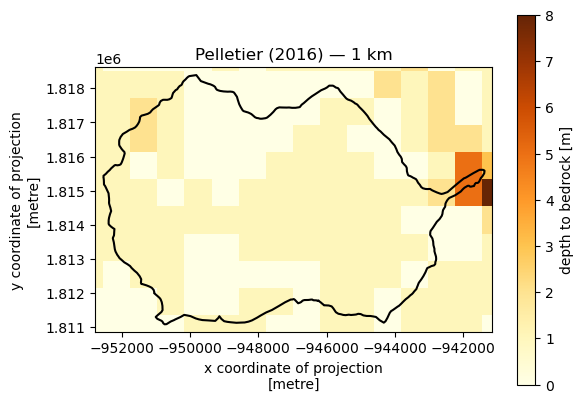

In [15]:
# plot Pelletier DTB
fig, ax = plt.subplots(1, 1)
pell_dtb.plot.imshow(ax=ax, cmap='YlOrBr', add_colorbar=True,
                 cbar_kwargs={'label': 'depth to bedrock [m]'})
watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
ax.set_xlim(domain_xlim)
ax.set_ylim(domain_ylim)
ax.set_title('Pelletier (2016) — 1 km')

### Shangguan et al. (2017)

Shangguan et al. (2017) provides a global 250 m depth-to-bedrock raster derived from a machine-learning model trained on borehole observations, terrain attributes, and soil and lithological maps.  Compared to Pelletier (1 km), this product offers finer spatial resolution and a more data-driven approach.

.. note:: Download ``BDTICM_M_250m_ll.zip`` from http://globalchange.bnu.edu.cn/research/dtbd.jsp, unzip it, and place the TIF at ``<data_directory>/soil_structure/Shangguan2017/BDTICM_M_250m_ll.tif``.

Shangguan, W., Hengl, T., Mendes de Jesus, J., Yuan, H., and Dai, Y. (2017). Mapping the global depth to bedrock for land surface modeling. *Journal of Advances in Modeling Earth Systems*, 9, 65–88. https://doi.org/10.1002/2016MS000686

In [16]:
shan_mgr = watershed_workflow.sources.ManagerShangguanDTB()
shan_dtb = shan_mgr.getDataset(watershed.geometry[0], watershed.crs, out_crs=crs)['band_1']
print(shan_dtb)

2026-07-24 21:32:47,426 - root - INFO: Incoming shape area = 0.005521611592362775
2026-07-24 21:32:47,427 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.006249999000000001
2026-07-24 21:32:47,427 - root - INFO: ... buffered shape area = 0.00783237124222674


<xarray.DataArray 'band_1' (y: 54, x: 69)> Size: 15kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(54, 69), dtype=float32)
Coordinates:
  * y            (y) float64 432B 1.809e+06 1.809e+06 ... 1.819e+06 1.82e+06
  * x            (x) float64 552B -9.537e+05 -9.535e+05 ... -9.406e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    units:          m
    description:    Depth to bedrock


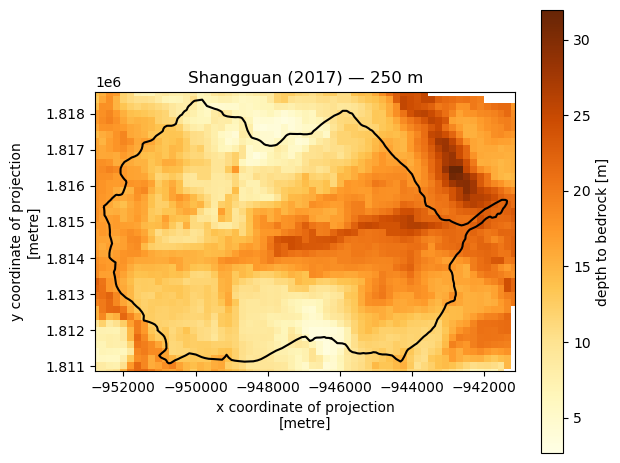

In [17]:
# Shangguan DTB
fig, ax = plt.subplots(1, 1)
shan_dtb.plot.imshow(ax=ax, cmap='YlOrBr', add_colorbar=True,
                 cbar_kwargs={'label': 'depth to bedrock [m]'})
watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
ax.set_xlim(domain_xlim)
ax.set_ylim(domain_ylim)
ax.set_title('Shangguan (2017) — 250 m')
plt.tight_layout()

### SSURGO

The NRCS's SSURGO/STATSGO products provide shape-based information about the top 2m of soil.  This data is provided by formation, and includes multiple formations (map-units), in which each map unit has (potentially) multiple components and each component has (potentially) multiple horizons.  Short of taking the most prevelant component, we must average, so we tend to average horizons and components and just apply this uniformly in the top 2m.  Provided include a complete set of parameters:

* porosity
* permeability
* bulk density
* texture
* and more...

Unfortunately, while map units seem to cover the area of interest, they don't all have at least one horizon with valid data, so some formations end up with NaN values.  So while SSURGO can be used as an "overlay" with good soil layer information, it cannot be used alone without a gap-filling plan.

Additionally, some locations have texture data but not porosity or permeability -- we can use Rosetta to simulate these properties from the texture info.

Soil Survey Staff, Natural Resources Conservation Service, United States Department of Agriculture. Soil Survey Geographic (SSURGO) Database. https://sdmdataaccess.nrcs.usda.gov

Schaap, M. G., Leij, F. J., & van Genuchten, M. T. (2001). Rosetta: a computer program for estimating soil hydraulic parameters with hierarchical pedotransfer functions. *Journal of Hydrology*, 251(3–4), 163–176. https://doi.org/10.1016/S0022-1694(01)00466-8

In [18]:
# ssurgo
nrcs_mgr = watershed_workflow.sources.ManagerNRCS()
nrcs_gdf = nrcs_mgr.getShapesByGeometry(watershed.geometry[0], watershed.crs, out_crs=crs)
nrcs_gdf

2026-07-24 21:32:47,592 - root - INFO:   Shapes manager: buffered+snapped query box = (-107.11, 38.824, -106.974, 38.898)
2026-07-24 21:32:47,598 - root - INFO: fixing column: geometry


,mukey,residual saturation [-],Rosetta porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],Rosetta permeability [m^2],thickness [m],permeability [m^2],porosity [-],bulk density [g/cm^3],total sand pct [%],total silt pct [%],total clay pct [%],source,geometry,ID,name
0,498185,0.240269,0.502882,0.000092,1.319916,3.617805e-13,1.520000,2.279759e-13,0.265563,1.207632,32.946001,24.529703,42.524296,NRCS,"POLYGON ((-944785.13 1816692.421, -944749.93 1...",498185,NRCS-498185
2,498205,0.181598,0.399993,0.000139,1.457559,4.938634e-13,1.520000,2.734080e-12,0.159737,1.413553,63.518421,22.988158,13.493421,NRCS,"MULTIPOLYGON (((-941326.442 1813975.517, -9414...",498205,NRCS-498205
3,498206,0.181598,0.399993,0.000139,1.457559,4.938634e-13,1.520000,2.734080e-12,0.159737,1.413553,63.518421,22.988158,13.493421,NRCS,"MULTIPOLYGON (((-941547.739 1815002.315, -9416...",498206,NRCS-498206
4,498208,0.208316,0.428990,0.000071,1.420938,2.830658e-13,1.520000,1.184189e-12,0.185986,1.302697,40.662797,38.201188,21.136015,NRCS,"MULTIPOLYGON (((-942128.839 1815089.018, -9421...",498208,NRCS-498208
7,498231,0.213285,0.466663,0.000059,1.416784,3.782943e-13,1.070000,7.331979e-13,0.403218,1.197010,32.639846,41.078960,26.281194,NRCS,"MULTIPOLYGON (((-945161.235 1814657.527, -9451...",498231,NRCS-498231
8,509477,0.175133,0.567740,0.000103,1.383180,2.438575e-12,1.520000,3.039095e-12,0.428779,0.807465,62.072368,17.973684,19.953947,NRCS,"MULTIPOLYGON (((-950816.128 1811281.342, -9508...",509477,NRCS-509477
9,509479,0.230885,0.378365,0.000079,1.374540,1.031721e-13,1.250000,3.172415e-12,NaN,1.524444,39.279352,38.916498,21.804150,NRCS,"MULTIPOLYGON (((-950052.446 1810584.355, -9501...",509479,NRCS-509479
10,509481,0.230885,0.378365,0.000079,1.374540,1.031721e-13,1.250000,3.172415e-12,NaN,1.524444,39.279352,38.916498,21.804150,NRCS,"MULTIPOLYGON (((-953249.718 1812037.844, -9532...",509481,NRCS-509481
11,509482,0.207877,0.369886,0.000092,1.397760,1.474479e-13,1.205000,4.654687e-12,NaN,1.530585,45.389069,37.890283,16.720648,NRCS,"MULTIPOLYGON (((-950532.93 1810780.243, -95052...",509482,NRCS-509482
12,509513,0.219597,0.445168,0.000072,1.395746,2.727324e-13,1.520000,9.122162e-13,0.237423,1.280039,38.422252,35.742028,25.835720,NRCS,"MULTIPOLYGON (((-952758.746 1816351.261, -9527...",509513,NRCS-509513


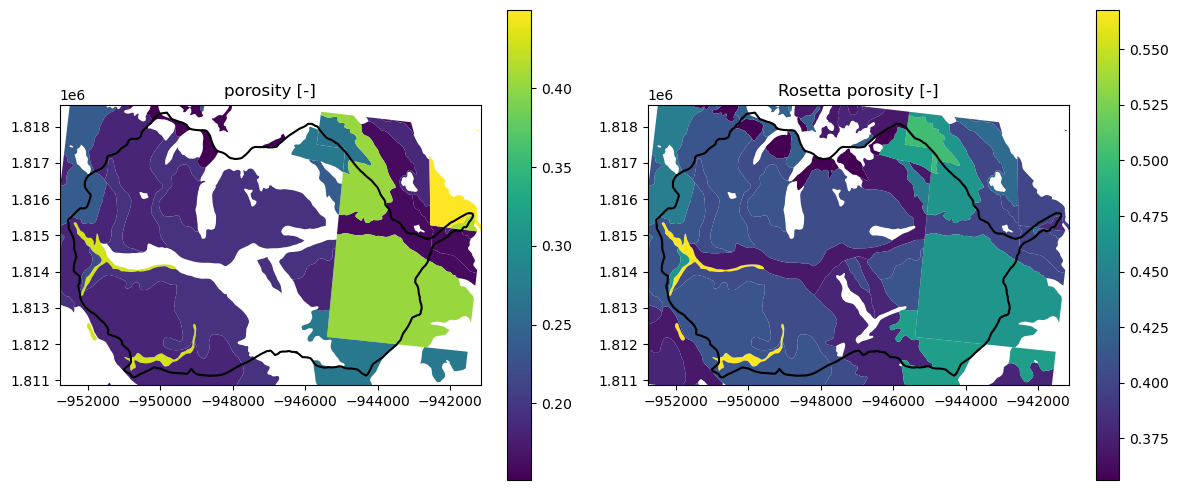

In [19]:
# plot ssurgo porosity, note white inside the domain is NaN values
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
nrcs_gdf.plot('porosity [-]', ax=axs[0], legend=True)
axs[0].set_title('porosity [-]')
nrcs_gdf.plot('Rosetta porosity [-]', ax=axs[1], legend=True)
axs[1].set_title('Rosetta porosity [-]')
for ax in axs:
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
plt.tight_layout()

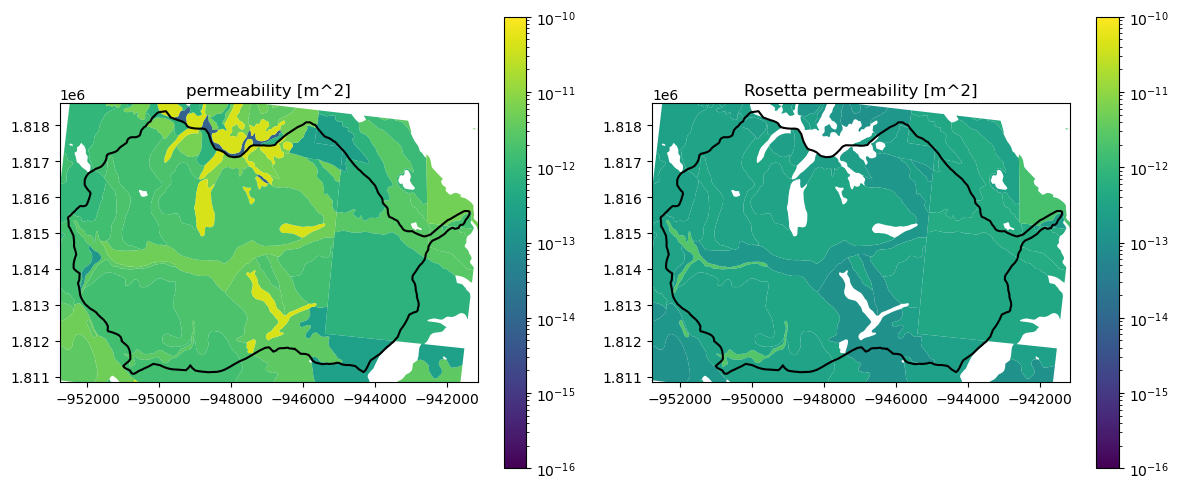

In [20]:
# plot ssurgo permeability, note white inside the domain is NaN values
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
nrcs_gdf.plot('permeability [m^2]', ax=axs[0], legend=True,
    norm=mcolors.LogNorm(vmin=1e-16, vmax=1e-10))
axs[0].set_title('permeability [m^2]')
nrcs_gdf.plot('Rosetta permeability [m^2]', ax=axs[1], legend=True,
              norm=mcolors.LogNorm(vmin=1e-16, vmax=1e-10))
axs[1].set_title('Rosetta permeability [m^2]')
for ax in axs:
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
plt.tight_layout()


### SoilGrids (2017)

SoilGrids 2017 provides 250 m global rasters of soil properties at 7 depth layers (0–200 cm), including:

* depth to bedrock (`BDTICM`)
* bulk density (`BLDFIE`)
* texture: percent sand (`SNDPPT`), silt (`SLTPPT`), clay (`CLYPPT`)
* organic carbon, pH, coarse fragments, and more

Layered variables are returned as 3D `(depth_to_horizon, y, x)` arrays where `depth_to_horizon` is the depth to the top of each horizon in metres.  Requesting a base variable name (e.g. `'SNDPPT'`) automatically expands to all 7 layers.

Note that here we use the 2017 product rather than 2020 because 2020 does not yet include depth-to-bedrock.

Hengl, T., et al. (2017). SoilGrids250m: Global gridded soil information based on machine learning. *PLOS ONE*, 12(2), e0169748. https://doi.org/10.1371/journal.pone.0169748

In [21]:
# SoilGrids 2017 — depth to bedrock
sg17_mgr = watershed_workflow.sources.ManagerSoilGrids2017()
sg17_dtb = sg17_mgr.getDataset(watershed.geometry[0], watershed.crs,
                                variables=['BDTICM'], out_crs=crs)['BDTICM']
print('BDTICM (depth to bedrock [m]):')
print(sg17_dtb)

2026-07-24 21:32:48,290 - root - INFO: Incoming shape area = 0.005521611592362775
2026-07-24 21:32:48,290 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.006737333812432626
2026-07-24 21:32:48,291 - root - INFO: ... buffered shape area = 0.008019382993854296


BDTICM (depth to bedrock [m]):
<xarray.DataArray 'BDTICM' (y: 55, x: 70)> Size: 15kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(55, 70), dtype=float32)
Coordinates:
  * y            (y) float64 440B 1.809e+06 1.809e+06 ... 1.82e+06 1.82e+06
  * x            (x) float64 560B -9.537e+05 -9.535e+05 ... -9.404e+05
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes: (12/29)
    ATTRIBUTE_LABEL:                   BDTICM_M
    ATTRIBUTE_MEASUREMENT_RESOLUTION:  1
    ATTRIBUTE_TITLE:                   Absolute depth to bedrock (in cm)
    ATTRIBUTE_UNITS_OF_MEASURE:        cm
    CITATION_ADDRESS:                  shanggv@bnu.edu.cn / tom.hengl@isric.org
    CITATION_ORIGINATOR:               College of Global Change and Earth Sys...
    ..

Text(0.5, 1.0, 'SoilGrids2017 BDTICM — depth to bedrock')

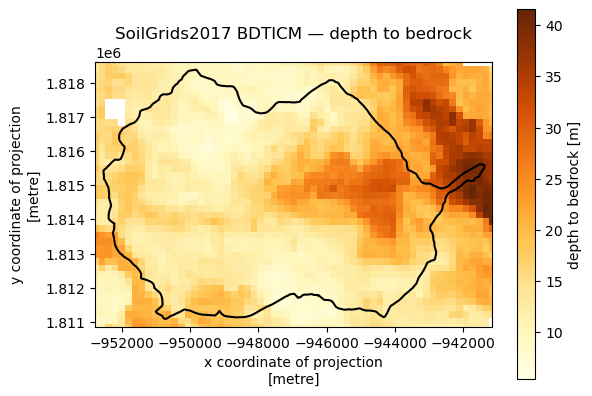

In [22]:
# Plot SoilGrids2017 depth to bedrock
fig, ax = plt.subplots(1, 1)
sg17_dtb.plot.imshow(ax=ax, cmap='YlOrBr', add_colorbar=True,
                     cbar_kwargs={'label': 'depth to bedrock [m]'})
watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
ax.set_xlim(domain_xlim)
ax.set_ylim(domain_ylim)
ax.set_title('SoilGrids2017 BDTICM — depth to bedrock')

### HydroFrame HF-Hydrodata CONUS2

The HydroFrame project provides the CONUS2 subsurface parameterization via the `hf_hydrodata` package.  The primary product is `pf_indicator`, a 3D integer grid (10 z-layers × y × x) on a 1-km Lambert Conformal Conic grid covering the continental US.  Each integer maps to a hydrogeologic unit with known properties (porosity, permeability, van Genuchten parameters, specific storage).

Compared to SSURGO and GLHYMPS:

* **Coverage**: CONUS-wide, no gaps, no missing data within the active domain
* **Resolution**: 1 km (coarser than SSURGO but complete)
* **Depth**: 10 layers to ~400 m depth
* **Properties**: a full property set is available via `getIndicatorTable()` — no Rosetta needed
* **Limitation**: requires a free HydroFrame account and PIN; PIN expires after a few days of non-use

This dataset is particularly well-suited as a bedrock/deep-subsurface layer to complement SSURGO's shallow soil information.

**Setup**: add to `~/.watershed_workflowrc`:
```ini
[HFHydrodata]
email = user@example.com
pin = 1234
```
Generate a PIN at https://hydrogen.princeton.edu/pin.

Maxwell, R. M., et al. (2015). The imprint of climate and geology on the residence times of groundwater. *Geophysical Research Letters*, 43(2), 701–708. https://doi.org/10.1002/2015GL066916

Yang, C., et al. (2023). CONUS2.0: A new integrated hydrologic simulation of the contiguous United States at high resolution. *Geoscientific Model Development*. https://doi.org/10.5194/gmd-2023-205

Leonarduzzi, E., et al. (2024). HydroData: A multi-scale hydrology dataset for the contiguous United States. *Earth and Space Science*, 11, e2023EA003021. https://doi.org/10.1029/2023EA003021

In [23]:
# Download the CONUS2 pf_indicator for the watershed
hfhd_mgr = watershed_workflow.sources.ManagerHFHydrodata()
hfhd_ds = hfhd_mgr.getDataset(watershed.geometry[0], watershed.crs, out_crs=crs)
hfhd_indicator = hfhd_ds['pf_indicator']
print(hfhd_indicator)

2026-07-24 21:32:48,459 - root - INFO: Incoming shape area = 0.005521611592362775
2026-07-24 21:32:48,459 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.026999999999999996
2026-07-24 21:32:48,461 - root - INFO: ... buffered shape area = 0.01692038260373745
2026-07-24 21:32:48,462 - root - INFO: ManagerHFHydrodata: cache hit at /Users/uec/code/watershed_workflow/data/soil_structure/parflow_conus2/hydroframe_hf_hydrodata/hydroframe_hf_hydrodata_-107.1360_38.7990_-106.9470_38.9250


<xarray.DataArray 'pf_indicator' (z: 10, y: 11, x: 17)> Size: 7kB
array([[[19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19],
        ...,
        [19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19]],

       [[19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19],
        ...,
        [19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19]],

       [[19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 19],
        [19, 19, 19, ..., 19, 19, 20],
        ...,
...
        ...,
        [ 6,  6,  6, ...,  3,  3,  6],
        [ 6,  6,  6, ...,  6,  6,  6],
        [ 6,  6,  6, ...,  6,  6,  6]],

       [[ 6,  6,  6, ...,  6,  6,  6],
        [ 6,  6,  6, ...,  6,  6,  6],
        [ 6,  6,  6, ...,  6,  6,  6],
        ...,
        [ 6,  6,  6, ...,  3,  3,  6],
 

/var/folders/fj/y8h3hc4x3fx9jtychppwtybr0000gp/T/ipykernel_67039/3575715331.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', n)
/var/folders/fj/y8h3hc4x3fx9jtychppwtybr0000gp/T/ipykernel_67039/3575715331.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


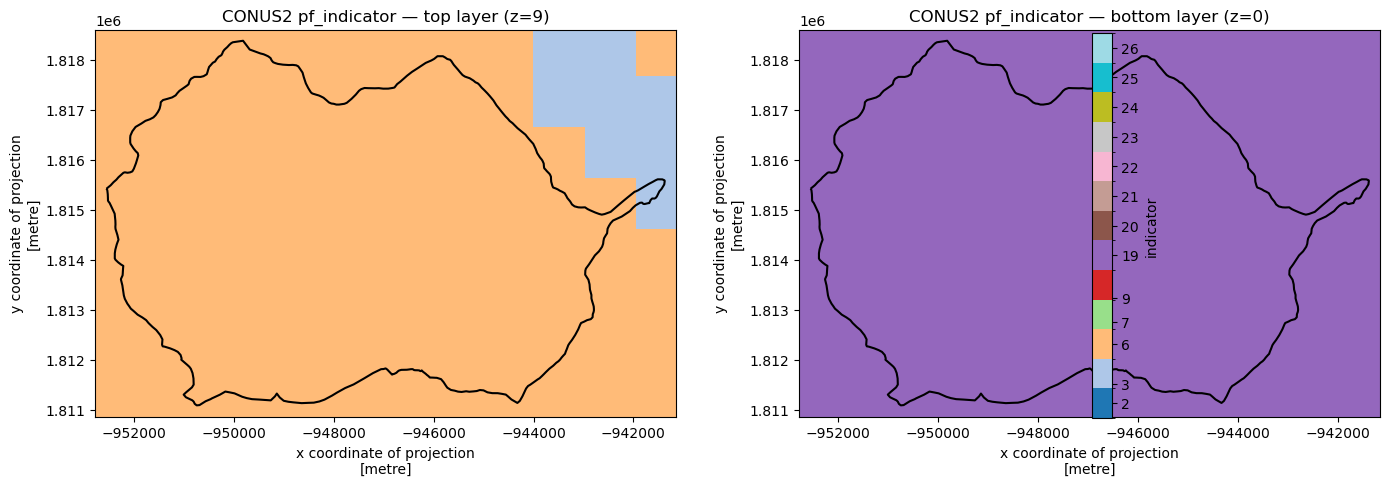

In [24]:
# Plot the indicator in the top-most and bottom layers
hfhd_present_ids = sorted(set(int(v) for v in hfhd_indicator.values.ravel() if not np.isnan(v)))
n = len(hfhd_present_ids)
cmap = plt.cm.get_cmap('tab20', n)
boundaries = [v - 0.5 for v in hfhd_present_ids] + [hfhd_present_ids[-1] + 0.5]
norm = mcolors.BoundaryNorm(boundaries, ncolors=n)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, z, title in [
    (axs[0], -1,  'CONUS2 pf_indicator — top layer (z=9)'),
    (axs[1], 0, 'CONUS2 pf_indicator — bottom layer (z=0)'),
]:
    hfhd_indicator.isel(z=z).plot.imshow(ax=ax, cmap=cmap, norm=norm, add_colorbar=False)
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
    ax.set_title(title)
    im = ax.collections[0] if ax.collections else ax.images[0]

fig.colorbar(
    plt.cm.ScalarMappable(cmap=cmap, norm=norm),
    ax=axs, ticks=hfhd_present_ids,
).set_label('indicator')
plt.tight_layout()


In [25]:
# Show the property lookup table for the indicators present in this watershed
hfhd_table = hfhd_mgr.getIndicatorTable()
hfhd_present = sorted(hfhd_indicator.values.astype(int).ravel().tolist())
hfhd_present_ids = sorted(set(hfhd_present))
hfhd_table.loc[hfhd_table.index.isin(hfhd_present_ids)]

,porosity,permeability_x,permeability_y,permeability_z,vg_alpha,vg_n,sres,specific_storage
indicator,,,,,,,,
2,0.390,0.043630,0.043630,0.043630,3.467,2.738,0.00010,0.0001
3,0.387,0.015841,0.015841,0.015841,2.692,2.445,0.00010,0.0001
6,0.399,0.005009,0.005009,0.005009,1.122,2.479,0.00010,0.0001
7,0.384,0.005493,0.005493,0.005493,2.089,2.318,0.00010,0.0001
9,0.442,0.003387,0.003387,0.003387,1.585,2.413,0.00010,0.0001
19,0.050,0.005000,0.005000,0.000500,0.500,2.500,0.00001,0.0001
20,0.100,0.010000,0.010000,0.001000,0.500,2.500,0.00001,0.0001
21,0.120,0.020000,0.020000,0.002000,0.500,2.500,0.00001,0.0001
22,0.300,0.030000,0.030000,0.003000,0.500,2.500,0.00001,0.0001


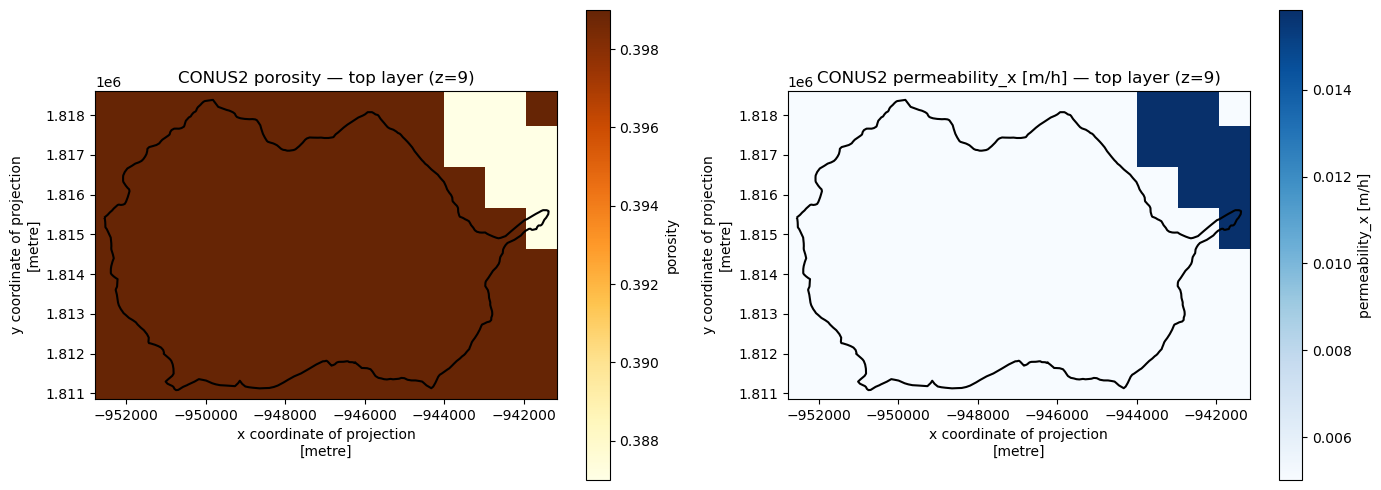

In [26]:
# Derive porosity and permeability_x fields by mapping indicator -> table value
hfhd_top = hfhd_indicator.isel(z=9)

hfhd_poro_vals = hfhd_table['porosity'].to_dict()
hfhd_perm_vals = hfhd_table['permeability_x'].to_dict()

hfhd_poro_data = np.vectorize(hfhd_poro_vals.get)(hfhd_top.values.astype(int))
hfhd_perm_data = np.vectorize(hfhd_perm_vals.get)(hfhd_top.values.astype(int))

hfhd_poro = xr.DataArray(hfhd_poro_data.astype(np.float32), coords=hfhd_top.coords, dims=hfhd_top.dims,
                        name='porosity')
hfhd_perm = xr.DataArray(hfhd_perm_data.astype(np.float32), coords=hfhd_top.coords, dims=hfhd_top.dims,
                        name='permeability_x [m/h]')

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
hfhd_poro.plot.imshow(ax=axs[0], cmap='YlOrBr', add_colorbar=True)
axs[0].set_title('CONUS2 porosity — top layer (z=9)')
hfhd_perm.plot.imshow(ax=axs[1], cmap='Blues', add_colorbar=True)
axs[1].set_title('CONUS2 permeability_x [m/h] — top layer (z=9)')
for ax in axs:
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
plt.tight_layout()


### SoilGrids 2.0

SoilGrids 2.0 provides 250 m global gridded soil properties at six standard GlobalSoilMap depth intervals (0–5, 5–15, 15–30, 30–60, 60–100, 100–200 cm).  Data are delivered via the ISRIC OGC WCS — no authentication required, CC-BY 4.0 license.

Available variables include bulk density (`bdod`), clay/sand/silt content, soil organic carbon (`soc`), pH in water (`phh2o`), coarse fragments (`cfvo`), nitrogen, and organic carbon density (`ocd`).  The default request fetches the four texture variables needed for Rosetta (`clay`, `sand`, `silt`, `bdod`) and automatically computes van Genuchten parameters pixel-by-pixel.

Compared to SSURGO and GLHYMPS:

* **Coverage**: global, no gaps within land areas
* **Resolution**: 250 m raster (finer than CONUS2, coarser than SSURGO map units)
* **Depth**: six layers to 2 m
* **Properties**: full VG parameter set derived via Rosetta; no depth-to-bedrock in v2.0 (use Pelletier for that)
* **Limitation**: purely statistical model — accuracy varies by region and depth

Poggio, L., et al. (2021). SoilGrids 2.0: producing soil information for the globe with quantified spatial uncertainty. *SOIL*, 7, 217–240. https://doi.org/10.5194/soil-7-217-2021

In [27]:
# Download SoilGrids 2.0 default variables (clay, sand, silt, bdod) for the watershed.
# Rosetta is run automatically because all four texture variables are present.
sg2_mgr = watershed_workflow.sources.ManagerSoilGrids()
sg2_ds = sg2_mgr.getDataset(watershed.geometry[0], watershed.crs, out_crs=crs)
print(sg2_ds)

2026-07-24 21:32:49,023 - root - INFO: Incoming shape area = 0.005521611592362775
2026-07-24 21:32:49,023 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.006
2026-07-24 21:32:49,024 - root - INFO: ... buffered shape area = 0.007736872189567648
2026-07-24 21:32:49,025 - root - INFO: ManagerSoilGrids: cache hit at /Users/uec/code/watershed_workflow/data/soil_structure/soilgrids/isric_wcs/isric_wcs_-107.1140_38.8200_-106.9700_38.9020
2026-07-24 21:32:49,033 - root - INFO:   Running Rosetta on SoilGrids texture rasters
2026-07-24 21:32:49,034 - root - INFO: Running Rosetta for van Genutchen parameters
2026-07-24 21:32:52,320 - root - INFO:   ... done


<xarray.Dataset> Size: 888kB
Dimensions:                      (x: 72, y: 57, depth: 6)
Coordinates:
  * x                            (x) float64 576B -9.537e+05 ... -9.405e+05
  * y                            (y) float64 456B 1.809e+06 ... 1.82e+06
  * depth                        (depth) float32 24B 0.025 0.1 0.225 ... 0.8 1.5
    spatial_ref                  int64 8B 0
Data variables:
    clay                         (depth, y, x) float32 98kB nan nan ... nan nan
    sand                         (depth, y, x) float32 98kB nan nan ... nan nan
    silt                         (depth, y, x) float32 98kB nan nan ... nan nan
    bdod                         (depth, y, x) float32 98kB nan nan ... nan nan
    residual saturation [-]      (depth, y, x) float32 98kB nan nan ... nan nan
    porosity [-]                 (depth, y, x) float32 98kB nan nan ... nan nan
    van Genuchten alpha [Pa^-1]  (depth, y, x) float32 98kB nan nan ... nan nan
    van Genuchten n [-]          (depth, y, x) flo

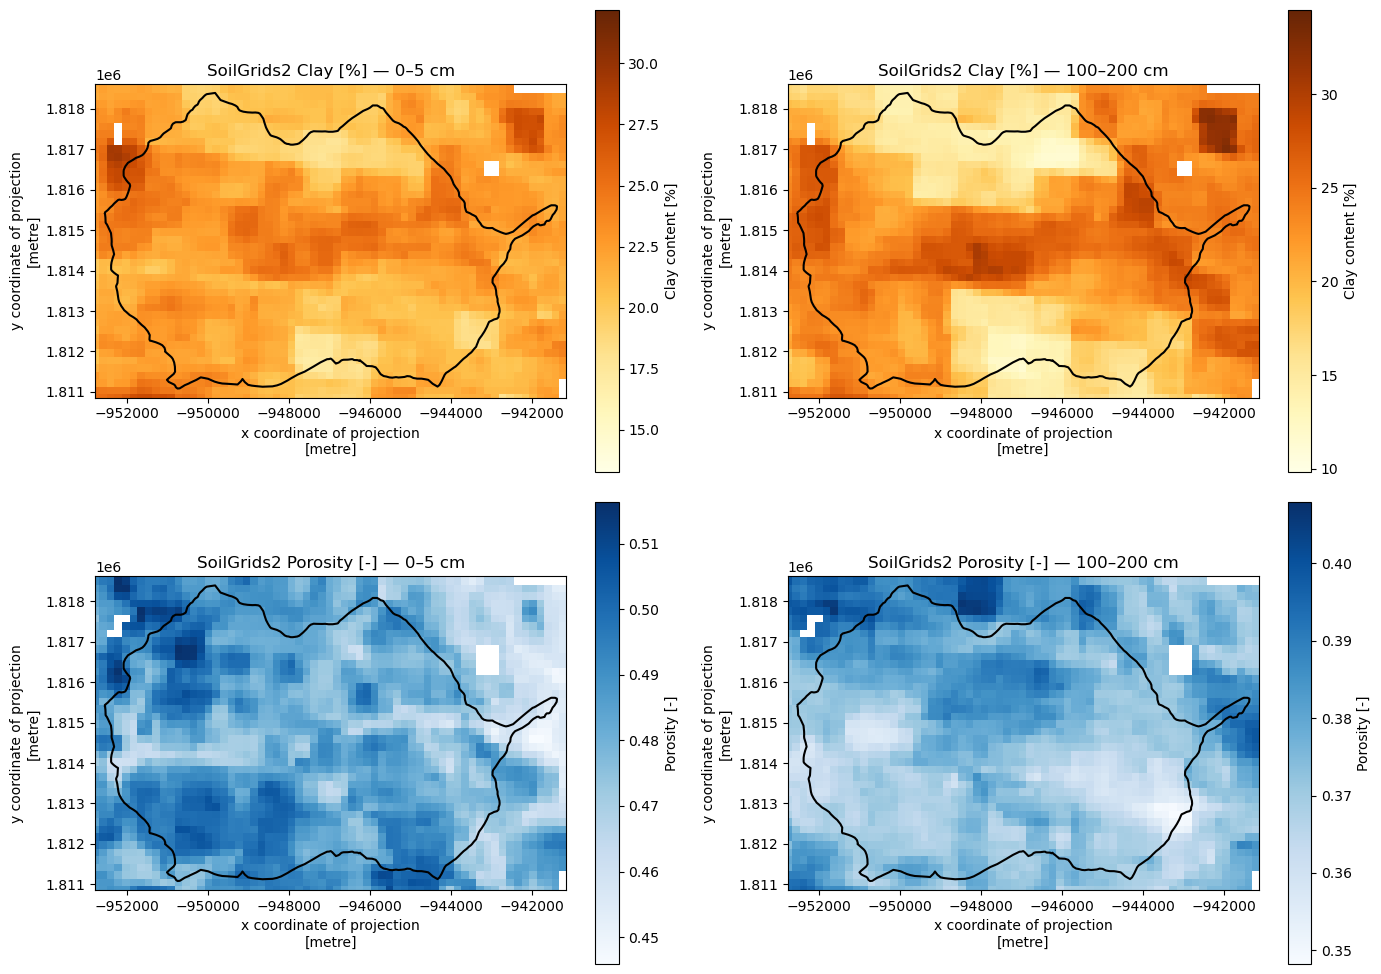

In [28]:
# Plot clay content and porosity at the shallowest and deepest layers
# Rows: clay (top), porosity (bottom).  Columns: 0-5 cm (left), 100-200 cm (right).
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
plots = [
    (0, 0, 'clay',         'Clay [%]',     'YlOrBr',  0),
    (0, 1, 'clay',         'Clay [%]',     'YlOrBr', -1),
    (1, 0, 'porosity [-]', 'Porosity [-]', 'Blues',   0),
    (1, 1, 'porosity [-]', 'Porosity [-]', 'Blues',  -1),
]
depth_titles = ['0–5 cm', '100–200 cm']
for row, col, var, label, cmap, z_idx in plots:
    ax = axs[row, col]
    sg2_ds[var].isel(depth=z_idx).plot.imshow(ax=ax, cmap=cmap, add_colorbar=True)
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
    ax.set_title(f'SoilGrids2 {label} — {depth_titles[col]}')
plt.tight_layout()

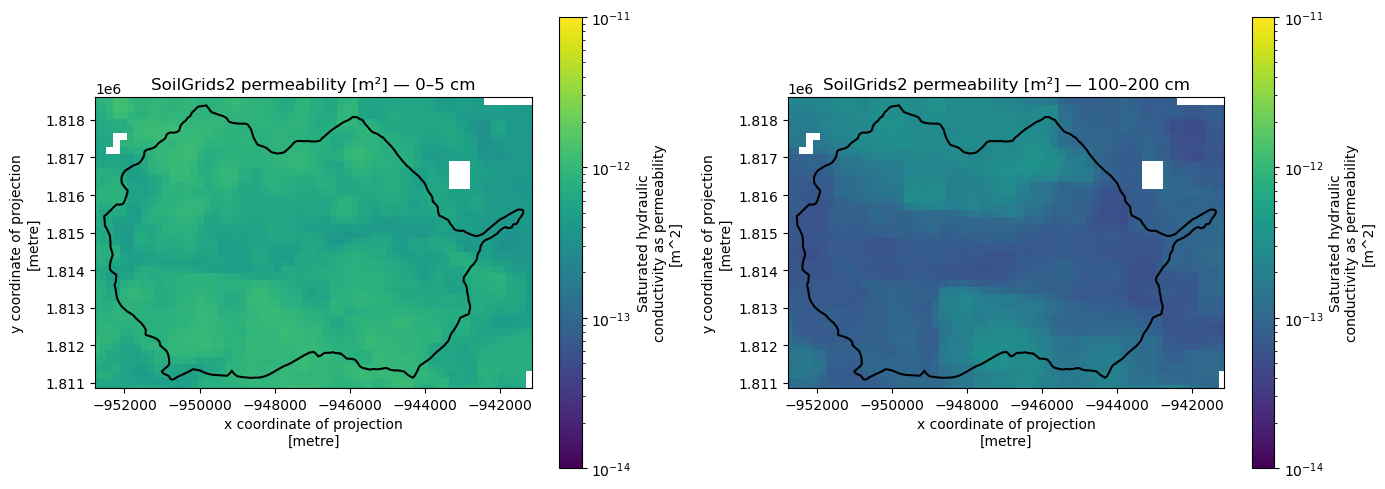

In [29]:
# Plot log10(permeability) at the shallowest and deepest layers
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, z_idx, title in [
    (axs[0],  0, 'SoilGrids2 permeability [m²] — 0–5 cm'),
    (axs[1], -1, 'SoilGrids2 permeability [m²] — 100–200 cm'),
]:
    sg2_ds['permeability [m^2]'].isel(depth=z_idx).plot.imshow(
        ax=ax, cmap='viridis',
        norm=mcolors.LogNorm(vmin=1e-14, vmax=1e-11),
        add_colorbar=True)
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
    ax.set_title(title)
plt.tight_layout()


### POLARIS (30 m CONUS)

POLARIS provides 30-m resolution, spatially continuous, probabilistic maps of soil hydraulic properties for the contiguous United States (CONUS).  Unlike SSURGO polygon-based data or CONUS2 indicator classes, POLARIS delivers **continuous float fields** directly — van Genuchten parameters (θ_r, θ_s, α, n) and saturated hydraulic conductivity (K_sat) are pre-computed at each 30-m pixel without needing Rosetta.

Data are served as plain-HTTP GeoTIFFs tiled by 1-degree cells.  No authentication is required.

Available variables include clay, sand, silt, organic matter (), bulk density (), pH, bubbling pressure (), and the full set of hydraulic parameters:  (log₁₀ cm/hr),  (log₁₀ cm⁻¹), , , .

Compared to SoilGrids 2.0:

* **Coverage**: CONUS only (SoilGrids is global)
* **Resolution**: 30 m raster (much finer than SoilGrids 250 m)
* **Depth**: same six layers to 2 m
* **Properties**: VG parameters provided directly — no Rosetta step needed
* **Units note**:  and  are stored as log₁₀ values

**License**: CC BY-NC 4.0

Chaney, N.W., Minasny, B., Herman, J.D., Nauman, T.W., Brungard, C.W., Morgan, C.L.S., McBratney, A.B., Wood, E.F., and Yimam, Y. (2019). POLARIS soil properties: 30-m probabilistic maps of soil properties over the contiguous United States. *Water Resources Research*, 55, 2916–2938. https://doi.org/10.1029/2018WR022797

In [30]:
# Download POLARIS default variables (theta_s, theta_r, alpha, n, ksat) for the watershed.
# VG parameters are provided directly — no Rosetta step needed.
polaris_mgr = watershed_workflow.sources.ManagerPOLARIS()
polaris_ds = polaris_mgr.getDataset(watershed.geometry[0], watershed.crs, out_crs=crs)
print(polaris_ds)

2026-07-24 21:32:53,190 - root - INFO: Incoming shape area = 0.005521611592362775
2026-07-24 21:32:53,191 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.0008339999999999999
2026-07-24 21:32:53,191 - root - INFO: ... buffered shape area = 0.005821068049095576
2026-07-24 21:32:53,192 - root - INFO: ManagerPOLARIS: cache hit at /Users/uec/code/watershed_workflow/data/soil_structure/polaris/duke_polaris_https/duke_polaris_https_-107.1073_38.8269_-106.9763_38.8958


<xarray.Dataset> Size: 20MB
Dimensions:      (x: 471, y: 351, depth: 6)
Coordinates:
  * x            (x) float64 4kB -9.531e+05 -9.531e+05 ... -9.411e+05 -9.411e+05
  * y            (y) float64 3kB 1.81e+06 1.81e+06 ... 1.819e+06 1.819e+06
  * depth        (depth) float32 24B 0.025 0.1 0.225 0.45 0.8 1.5
    spatial_ref  int64 8B 0
Data variables:
    theta_s      (depth, y, x) float32 4MB nan nan nan nan ... nan nan nan nan
    theta_r      (depth, y, x) float32 4MB nan nan nan nan ... nan nan nan nan
    alpha        (depth, y, x) float32 4MB nan nan nan nan ... nan nan nan nan
    n            (depth, y, x) float32 4MB nan nan nan nan ... nan nan nan nan
    ksat         (depth, y, x) float32 4MB nan nan nan nan ... nan nan nan nan
Attributes:
    source:    Duke Hydrology Lab
    variable:  theta_s
    stat:      mean
    product:   POLARIS


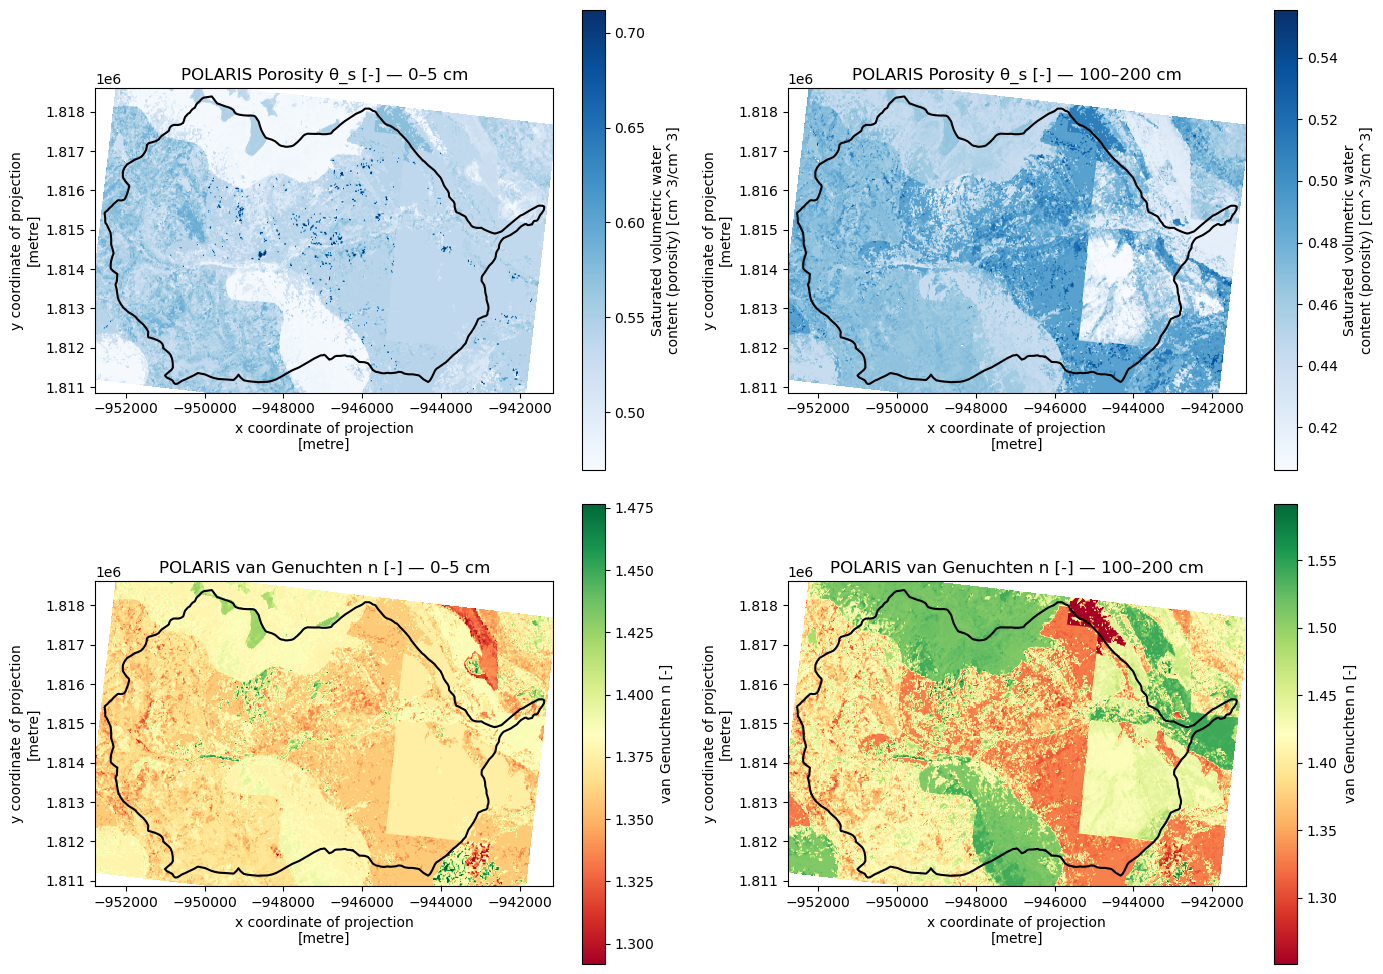

In [31]:
# Plot theta_s (porosity) and van Genuchten n at shallowest and deepest layers.
# Rows: theta_s (top), n (bottom).  Columns: 0-5 cm (left), 100-200 cm (right).
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
plots = [
    (0, 0, 'theta_s', 'Porosity θ_s [-]',   'Blues',   0),
    (0, 1, 'theta_s', 'Porosity θ_s [-]',   'Blues',  -1),
    (1, 0, 'n',       'van Genuchten n [-]', 'RdYlGn',  0),
    (1, 1, 'n',       'van Genuchten n [-]', 'RdYlGn', -1),
]
depth_titles = ['0–5 cm', '100–200 cm']
for row, col, var, label, cmap, z_idx in plots:
    ax = axs[row, col]
    polaris_ds[var].isel(depth=z_idx).plot.imshow(ax=ax, cmap=cmap, add_colorbar=True)
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
    ax.set_title(f'POLARIS {label} — {depth_titles[col]}')
plt.tight_layout()

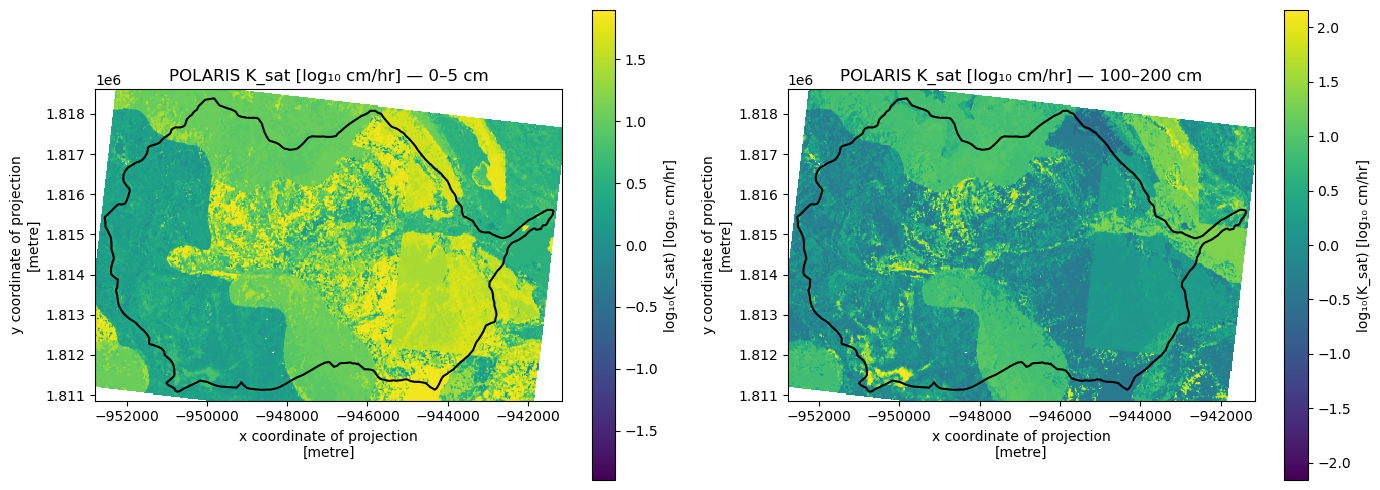

In [32]:
# Plot K_sat (stored as log10(cm/hr)) at shallowest and deepest layers.
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, z_idx, title in [
    (axs[0],  0, 'POLARIS K_sat [log₁₀ cm/hr] — 0–5 cm'),
    (axs[1], -1, 'POLARIS K_sat [log₁₀ cm/hr] — 100–200 cm'),
]:
    polaris_ds['ksat'].isel(depth=z_idx).plot.imshow(
        ax=ax, cmap='viridis', add_colorbar=True,
        cbar_kwargs={'label': 'log₁₀(K_sat) [log₁₀ cm/hr]'}
    )
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
    ax.set_title(title)
plt.tight_layout()


## Product Comparison

This section compares datasets side-by-side across the same domain with consistent colorbar ranges for direct visual comparison.

### Depth-to-Bedrock Comparison

Pelletier (1 km), Shangguan (250 m), and SoilGrids2017 (250 m) side-by-side, all in metres with a shared colorbar.

DTB colorbar: 0 – 39 m


/var/folders/fj/y8h3hc4x3fx9jtychppwtybr0000gp/T/ipykernel_67039/3848242146.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


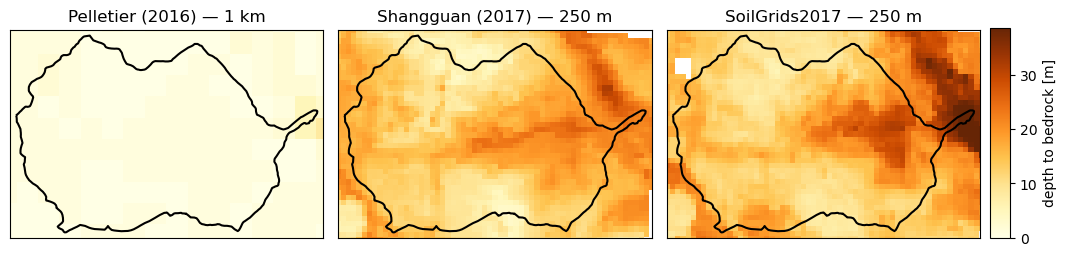

In [33]:
# DTB comparison — Pelletier, Shangguan, SoilGrids2017, shared colorbar [m]
# All rasters are already in the common projected CRS.
dtb_vmin = 0.0
dtb_vmax = float(max(
    float(np.nanquantile(pell_dtb.values, 0.99)),
    float(np.nanquantile(shan_dtb.values, 0.99)),
    float(np.nanquantile(sg17_dtb.values, 0.99)),
))
print(f'DTB colorbar: 0 – {dtb_vmax:.0f} m')

fig, axs = plt.subplots(1, 3, figsize=(10, 3))
for ax, da, title in [
    (axs[0], pell_dtb,     'Pelletier (2016) — 1 km'),
    (axs[1], shan_dtb,     'Shangguan (2017) — 250 m'),
    (axs[2], sg17_dtb, 'SoilGrids2017 — 250 m'),
]:
    da.plot.imshow(ax=ax, cmap='YlOrBr', vmin=dtb_vmin, vmax=dtb_vmax, add_colorbar=False)
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_xlabel('')
    ax.set_yticks([])
    ax.set_ylabel('')

sm = mcm.ScalarMappable(cmap='YlOrBr', norm=mcolors.Normalize(vmin=dtb_vmin, vmax=dtb_vmax))
sm.set_array([])
cax = fig.add_axes([0.995, 0.155, 0.02, 0.7])
fig.colorbar(sm, cax=cax, orientation='vertical', label='depth to bedrock [m]')
plt.tight_layout()


### Porosity Comparison (Top Soil Layer)

Porosity at the shallowest depth from every product that provides it, with a shared colorbar.  For raster products (SoilGrids 2.0, POLARIS) the 0–5 cm layer is used; for CONUS2 the topmost z-layer (z=0) is used.  GLHYMPS and SSURGO are polygon datasets plotted in their native formation geometry.

Note that each product covers different spatial extents and resolutions, and SSURGO may have NaN gaps where no horizon data were reported.

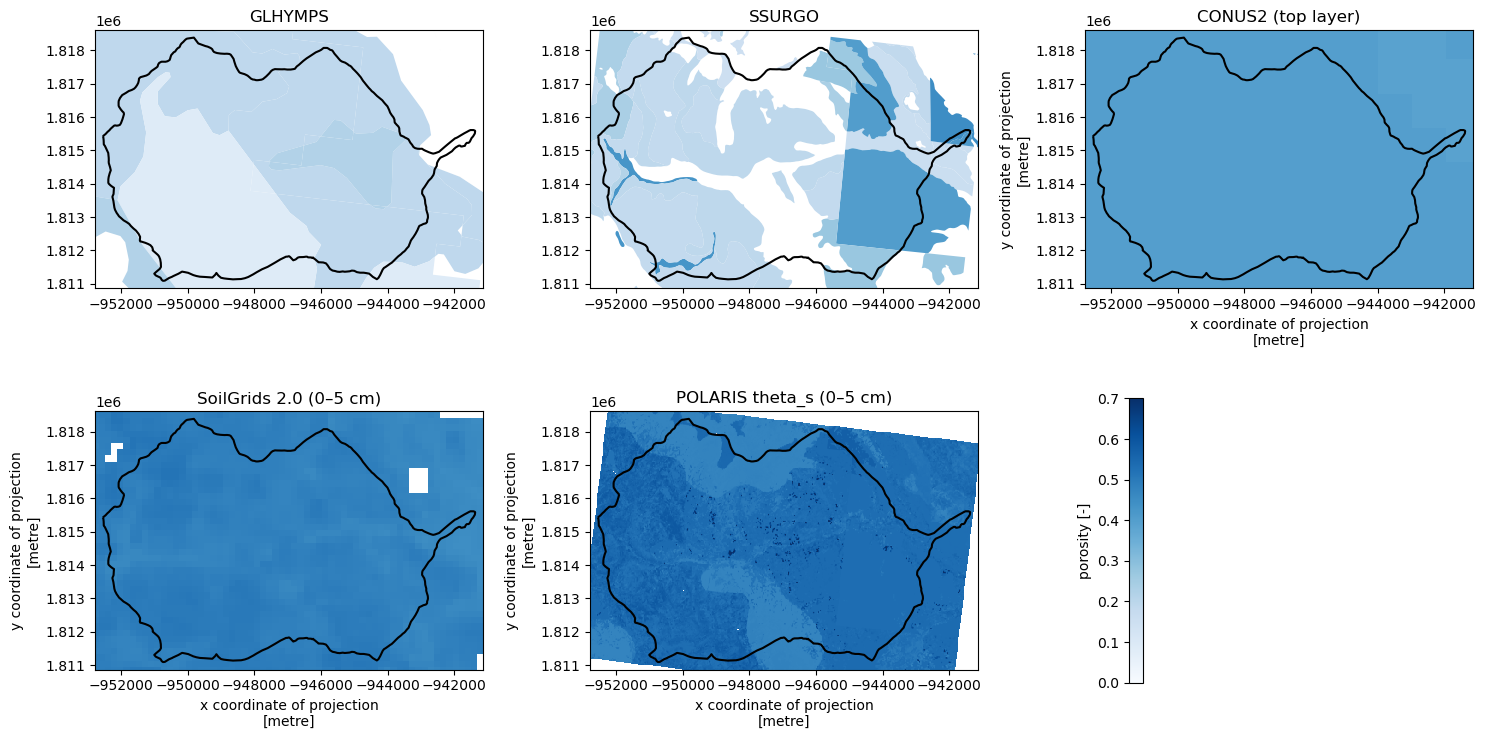

In [34]:
# Porosity comparison — top layer, shared colorbar in the 6th (unused) slot
# All datasets are in the common projected CRS.
poro_cmap = 'Blues'
poro_norm = mcolors.Normalize(vmin=0.0, vmax=0.7)

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
axs = axs.ravel()

# 1. GLHYMPS (polygon)
gl_gdf.plot(column='porosity [-]', ax=axs[0], cmap=poro_cmap, norm=poro_norm, legend=False)
axs[0].set_title('GLHYMPS')

# 2. SSURGO (polygon)
nrcs_gdf.plot(column='porosity [-]', ax=axs[1], cmap=poro_cmap, norm=poro_norm, legend=False)
axs[1].set_title('SSURGO')

# 3. CONUS2 (top z-layer, porosity derived from indicator table in cell above)
hfhd_poro.plot.imshow(ax=axs[2], cmap=poro_cmap, norm=poro_norm, add_colorbar=False)
axs[2].set_title('CONUS2 (top layer)')

# 4. SoilGrids 2.0 (0–5 cm)
sg2_ds['porosity [-]'].isel(depth=0).plot.imshow(
    ax=axs[3], cmap=poro_cmap, norm=poro_norm, add_colorbar=False)
axs[3].set_title('SoilGrids 2.0 (0–5 cm)')

# 5. POLARIS — theta_s is saturated volumetric water content (= porosity)
polaris_ds['theta_s'].isel(depth=0).plot.imshow(
    ax=axs[4], cmap=poro_cmap, norm=poro_norm, add_colorbar=False)
axs[4].set_title('POLARIS theta_s (0–5 cm)')

for ax in axs[:5]:
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)

# Colorbar in the 6th slot
axs[5].set_visible(False)
sm = mcm.ScalarMappable(cmap=poro_cmap, norm=poro_norm)
sm.set_array([])
fig.colorbar(sm, ax=axs[5], location='left', shrink=0.8,
             label='porosity [-]')
plt.tight_layout()


### Permeability Comparison (Top Soil Layer)

Intrinsic permeability [m²] at the shallowest depth from every product that provides it, plotted on a log scale with a shared colorbar.

Unit conversions applied inline (a future `standardize()` method on each manager will handle this automatically):

- **GLHYMPS / SSURGO / SoilGrids 2.0**: already in m².
- **CONUS2**: `permeability_x` column is saturated hydraulic conductivity Kₛ [m/h]; converted via *k = Kₛ μ / (ρ g)* with μ = 10⁻³ Pa·s, ρ = 1000 kg/m³, g = 9.81 m/s².
- **POLARIS**: `ksat` is log₁₀(Kₛ [cm/hr]); same formula after unit conversion to m/s.

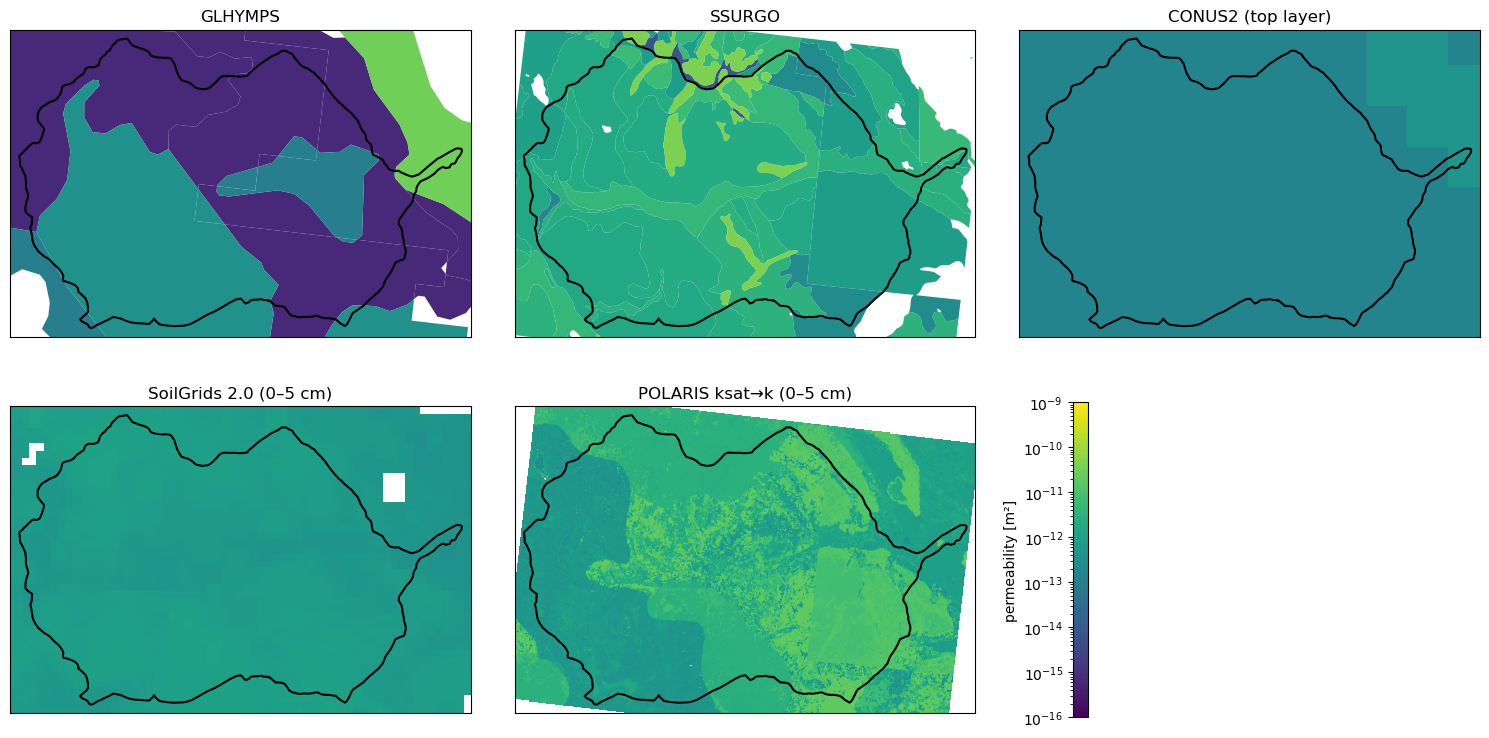

In [35]:
# Permeability comparison — top layer, shared log colorbar in the 6th (unused) slot
# All datasets are in the common projected CRS.
# k [m^2] = Ks [m/s] * mu / (rho * g)
MU, RHO, G = 1e-3, 1000.0, 9.81
KS_TO_PERM = MU / (RHO * G)   # ~1.019e-7  m^2 / (m/s)

# CONUS2: permeability_x [m/h] -> Ks [m/s] -> k [m^2]
hfhd_perm_top = hfhd_perm / 3600.0 * KS_TO_PERM

# POLARIS: ksat = log10(Ks [cm/hr]) -> Ks [m/s] -> k [m^2]
polaris_perm_top = (10 ** polaris_ds['ksat'].isel(depth=0)) * (1e-2 / 3600.0) * KS_TO_PERM

perm_cmap = 'viridis'
perm_norm = mcolors.LogNorm(vmin=1e-16, vmax=1e-9)

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
axs = axs.ravel()

# 1. GLHYMPS
gl_gdf.plot(column='permeability [m^2]', ax=axs[0], cmap=perm_cmap, norm=perm_norm, legend=False)
axs[0].set_title('GLHYMPS')

# 2. SSURGO
nrcs_gdf.plot(column='permeability [m^2]', ax=axs[1], cmap=perm_cmap, norm=perm_norm, legend=False)
axs[1].set_title('SSURGO')

# 3. CONUS2
hfhd_perm_top.plot.imshow(ax=axs[2], cmap=perm_cmap, norm=perm_norm, add_colorbar=False)
axs[2].set_title('CONUS2 (top layer)')

# 4. SoilGrids 2.0
sg2_ds['permeability [m^2]'].isel(depth=0).plot.imshow(
    ax=axs[3], cmap=perm_cmap, norm=perm_norm, add_colorbar=False)
axs[3].set_title('SoilGrids 2.0 (0–5 cm)')

# 5. POLARIS
polaris_perm_top.plot.imshow(
    ax=axs[4], cmap=perm_cmap, norm=perm_norm, add_colorbar=False)
axs[4].set_title('POLARIS ksat→k (0–5 cm)')

for ax in axs[:5]:
    watershed.boundary.plot(ax=ax, color='k', linewidth=1.5)
    ax.set_xlim(domain_xlim)
    ax.set_ylim(domain_ylim)
    ax.set_xticks([])
    ax.set_xlabel('')
    ax.set_yticks([])
    ax.set_ylabel('')

# Colorbar in the 6th slot
axs[5].set_visible(False)
sm = mcm.ScalarMappable(cmap=perm_cmap, norm=perm_norm)
sm.set_array([])
fig.colorbar(sm, ax=axs[5], location='left', shrink=0.8,
             label='permeability [m²]')
plt.tight_layout()
